# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [44]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2


In [2]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
# Initialize S, theta and bias
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

In [4]:
# Auto-graded cell (S)
# Skip it

In [5]:
# Auto-graded cell (theta)
# Skip it

In [6]:
# Auto-graded cell (bias)
# Skip it

In [7]:
# Auto-graded cell (z)
# Skip it

In [8]:
# Auto-graded cell (probabilities)
# Skip it

In [9]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [10]:
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user": rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour": rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})


# 3. long_session
log["long_session"] = (log["duration_min"] > 30).astype(int)

In [11]:
# Auto graded cell (log)
# skip it

In [12]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
idx = np.random.choice(log.index, 12, replace=False)
log.loc[idx, "failed_attempts"] = np.random.randint(5, 11, 12)

In [13]:
# Autograded cell (Failed attempts)
# Skip it

In [14]:
# Insert 10 missing values randomly

# Write your code here

rows = np.random.choice(log.index, 10, replace=False)
cols = np.random.choice(["duration_min", "hour", "country"], 10)
log["hour"] = log["hour"].astype(float)
for r, c in zip(rows, cols):
    log.loc[r, c] = np.nan

In [15]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [16]:
# Write your code here
ru_log_at_least_five_attempts = ((log["country"] == "RU") & (log["failed_attempts"] >= 5)).sum()
print(ru_log_at_least_five_attempts)

# ru_log_at_least_five_attempts = ...

0


In [17]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [18]:
# Write your code here
user_max_failed_attempts = (log.groupby("user")["failed_attempts"].sum()
                               .sort_values(ascending=False).index[0])
print(user_max_failed_attempts)

# user_max_failed_attempts =

yacine


In [19]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
# Write your code here
log["long_session"] = (log["duration_min"] > 30).astype(int)
# log['long_session'] = ...

In [21]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

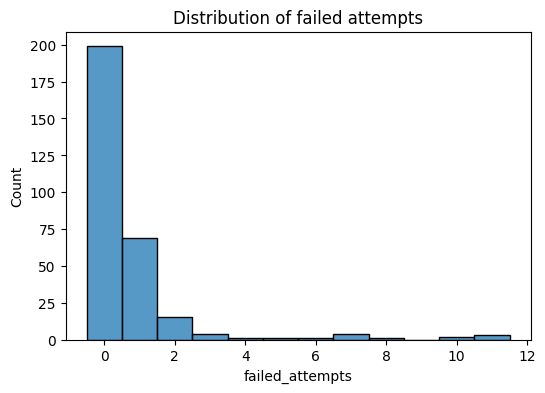

In [43]:
# Draw the histogram of failed_attempts.
# Write your code here
plt.figure(figsize=(6, 4))
sns.histplot(log["failed_attempts"], bins=range(0, 12), discrete=True)
plt.xlabel("failed_attempts"); plt.title("Distribution of failed attempts")
plt.show()

In [23]:
# Auto-graded cell - Skip it...

In [24]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [25]:
# Write your code here
answer_q2 = "B"

IndentationError: unexpected indent (4219836050.py, line 2)

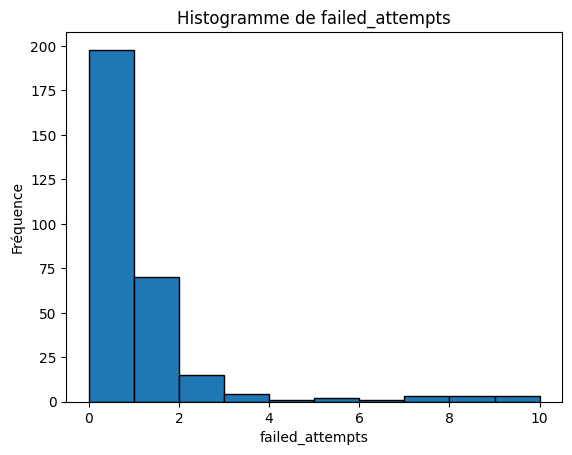

In [26]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

plt.figure()
plt.hist(log["failed_attempts"], bins=range(0, log["failed_attempts"].max() + 2), edgecolor="black")
plt.xlabel("failed_attempts"); plt.ylabel("Fréquence"); plt.title("Histogramme de failed_attempts")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
X[:, 2] returns the third column of X (index 2), for all 300 rows. This is the third feature of every sample, as a 1D array of shape (300,). (X itself has 300 samples and 4 features.)


Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [38]:
# Write your code here
df = pd.read_csv("logins.csv")
df.isna().sum()

,0
user,0
hour,0
failed_attempts,0
country,0
duration_min,10


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

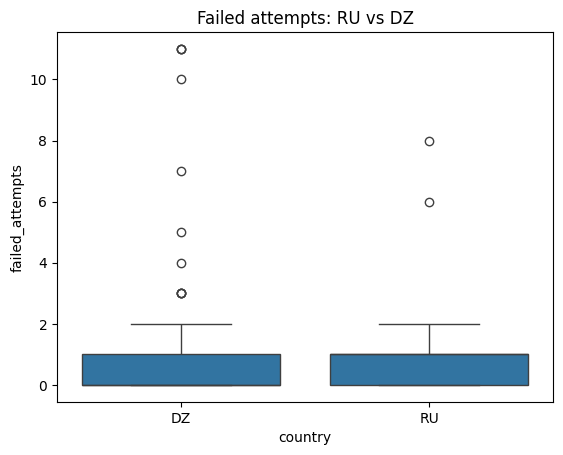

In [39]:
# Write your code here
df = pd.read_csv("logins.csv")
sns.boxplot(data=df[df["country"].isin(["RU", "DZ"])], x="country", y="failed_attempts")
plt.title("Failed attempts: RU vs DZ")
plt.xlabel("country")
plt.ylabel("failed_attempts")
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
We scale features so that they are all on the same scale, which prevents features with large values (like area) from dominating features with small values (like crime) and helps the model train faster and more stably.

Commit the logins_clean.csv.(0.5 point)

In [36]:
# save the cleaned table in login_clean.csv
# Write your code here
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user": rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour": rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})
log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 12, 12)
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan
log.to_csv("logins.csv", index=False)
print(log)

       user  hour  failed_attempts country  duration_min
0    yacine     2                0      DZ          24.0
1    yacine    23                0      FR          23.2
2      nour    11                0      FR           4.8
3     karim     9                0      DZ           4.2
4       ali    17                0      DZ          21.8
..      ...   ...              ...     ...           ...
295    nour    18                0      RU           5.2
296    nour    10                0      DZ           9.5
297  yacine     1                0      DZ           5.0
298   karim    15                2      TN          61.0
299     ali     3                1      DZ           7.2

[300 rows x 5 columns]


In [31]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [42]:
# Write your code here
log["duration_min"] = log["duration_min"].fillna(log["duration_min"].median())
log["night"] = (log["hour"] < 6).astype(int)
log.to_csv("logins_clean.csv", index=False)   # the filename is logins_clean.csv, not login_clean.csv as the comment says

df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy(dtype=float)
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scaled.shape)   # (300, 4)


(300, 4)


In [ ]:
import numpy as np
import pandas as pd
